# 이미지 분류 처음부터 — PyTorch + Intel GPU

**열어야 할 파일: `01_PyTorch_Intel_GPU.ipynb`**

현재 준비된 Python 3.14 / PyTorch XPU 환경과 `data/happy`, `data/sad` 이미지를 사용합니다.
이미지 준비 → 분할 → CNN 만들기 → 학습 → 평가 → 예측 → 저장 순서로 진행합니다.

이번 시작 설정:
- 이미지: **128×128 RGB**
- 배치: **8장**
- 학습: **3에포크**
- 장치: **Intel GPU (xpu)**
- 합성곱 3개를 사용하는 작은 CNN: **89,249개 파라미터**
- 각 배치의 진행 상황과 소요 시간 출력

기존 256×256 모델에서 입력 크기와 마지막 신경망 층을 줄였습니다.
이전 학습이 지연된 정확한 원인은 확인되지 않았습니다. 이 노트북은 계산량을 줄이고 지연 위치를 확인하기 쉽게 구성했습니다.

**시작하기**
1. 이전 노트북의 학습이 계속 `[*]`라면 그 노트북을 저장하고 **Kernel → Shut Down Kernel**로 종료합니다.
2. 이 새 노트북에서 **Python 3.14 (Intel GPU)** 커널을 선택합니다.
3. 처음에는 **Run All 대신 코드 셀을 하나씩 Shift+Enter**로 실행합니다.
4. 한 셀의 `[*]`가 실행 번호로 바뀌고 출력이 완료되면 다음 셀로 이동합니다.

커널 종료가 되지 않으면 실행 중인 기존 Jupyter 서버를 명령 프롬프트에서 Ctrl+C로 종료한 뒤 새 시작 파일을 실행하세요.
커널을 종료하면 메모리에만 있던 학습 상태는 사라집니다. 저장된 이미지·노트북·모델 파일은 유지됩니다.


# 1. Python과 GPU 확인
설치는 이미 완료되어 있으므로 먼저 환경을 확인합니다.
버전에 `+xpu`, GPU 사용 가능에 `True`가 나오는지 보세요.


In [2]:
import sys
import time
import random
import math
import json
from pathlib import Path
from datetime import datetime

print("PyTorch 불러오는 중...", flush=True)
import torch

print("Python:", sys.executable, flush=True)
print("Python 버전:", sys.version.split()[0], flush=True)
print("PyTorch:", torch.__version__, flush=True)
print("Intel GPU 사용 가능:", torch.xpu.is_available(), flush=True)

if not torch.xpu.is_available():
    raise RuntimeError(
        "Intel GPU를 찾지 못했습니다. Python 3.14 (Intel GPU) 커널을 선택했는지 확인하세요."
    )

device = torch.device("xpu:0")
print("GPU:", torch.xpu.get_device_name(0), flush=True)
print("1단계 완료", flush=True)


PyTorch 불러오는 중...
Python: C:\Users\박정원\ImageClassification\.venv-torch-xpu\Scripts\python.exe
Python 버전: 3.14.2
PyTorch: 2.14.1+xpu
Intel GPU 사용 가능: True
GPU: Intel(R) Arc(TM) 130T GPU (8GB)
1단계 완료


## GPU 계산 시작 확인
작은 계산을 실행하여 실제 GPU 작업이 완료되는지 확인합니다.
`GPU 계산 완료`가 출력되기 전에 다음 셀을 실행하지 마세요.
장치가 목록에 보이는 것과 실제 계산이 완료되는 것은 별개의 확인입니다.


In [3]:
print("작은 GPU 계산 시작...", flush=True)
gpu_start = time.perf_counter()

gpu_numbers = torch.tensor([1.0, 2.0, 3.0], device=device)
gpu_result = (gpu_numbers * 2).sum()
torch.xpu.synchronize()

print("GPU 계산 결과:", gpu_result.item(), "(정상 결과: 12.0)", flush=True)
print(f"GPU 계산 완료: {time.perf_counter() - gpu_start:.2f}초", flush=True)
del gpu_numbers, gpu_result


작은 GPU 계산 시작...
GPU 계산 결과: 12.0 (정상 결과: 12.0)
GPU 계산 완료: 0.67초


## 실행 설정
처음에는 아래 값을 그대로 사용하세요.
학습이 정상 진행되는 것을 확인한 뒤 `EPOCHS`를 늘릴 수 있습니다.
이미지 크기·배치 크기를 바꾸려면 커널을 재시작하고 위에서부터 실행하세요.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms

PROJECT_DIR = Path(r"C:\Users\박정원\ImageClassification")
DATA_DIR = PROJECT_DIR / "data"
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 8
EPOCHS = 3
LEARNING_RATE = 0.001
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.xpu.manual_seed_all(SEED)

print("이미지 폴더:", DATA_DIR)
print("이미지 크기:", IMAGE_SIZE)
print("배치 크기:", BATCH_SIZE)
print("학습 에포크:", EPOCHS)


이미지 폴더: C:\Users\박정원\ImageClassification\data
이미지 크기: (128, 128)
배치 크기: 8
학습 에포크: 3


# 2. 이미지 파일 확인
클래스 폴더 이름을 정답으로 사용합니다. 현재 데이터에서는 `happy=0`, `sad=1`입니다.
읽을 수 없는 파일은 목록에서 제외합니다. 원본 파일을 삭제하지 않습니다.
Pillow를 사용하므로 `imghdr`는 필요하지 않습니다.


In [8]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"이미지 폴더가 없습니다: {DATA_DIR}")

class_dirs = sorted(
    path for path in DATA_DIR.iterdir()
    if path.is_dir() and not path.name.startswith(".")
)
if len(class_dirs) != 2:
    raise ValueError(
        "이 노트북은 두 종류를 분류합니다. data 아래에 클래스 폴더가 정확히 2개 있어야 합니다."
    )

class_names = [path.name for path in class_dirs]
class_to_idx = {name: index for index, name in enumerate(class_names)}
samples = []
excluded = []
allowed_formats = {"JPEG", "PNG", "BMP"}

for label, class_dir in enumerate(class_dirs):
    file_paths = sorted(path for path in class_dir.rglob("*") if path.is_file())
    print(f"{class_dir.name}: 파일 {len(file_paths)}개 확인 시작", flush=True)

    for number, path in enumerate(file_paths, start=1):
        try:
            with Image.open(path) as image:
                if image.format not in allowed_formats:
                    raise ValueError(f"제외한 이미지 형식: {image.format}")
                image.verify()
            with Image.open(path) as image:
                image.convert("RGB").load()
            samples.append((path, label))
        except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as error:
            excluded.append((str(path), str(error)))

        if number % 25 == 0 or number == len(file_paths):
            print(f"  확인 {number}/{len(file_paths)}", flush=True)

for label, name in enumerate(class_names):
    count = sum(target == label for _, target in samples)
    print(f"{name}: 유효한 이미지 {count}장", flush=True)
    if count < 3:
        raise ValueError(f"{name}에 유효한 이미지가 최소 3장 필요합니다.")

print("분류 번호:", class_to_idx)
print("사용할 이미지:", len(samples), "/ 제외한 파일:", len(excluded))
for path, reason in excluded[:10]:
    print("제외:", path, "->", reason)


happy: 파일 153개 확인 시작
  확인 25/153
  확인 50/153
  확인 75/153
  확인 100/153
  확인 125/153
  확인 150/153
  확인 153/153
sad: 파일 152개 확인 시작
  확인 25/152
  확인 50/152
  확인 75/152
  확인 100/152
  확인 125/152
  확인 150/152
  확인 152/152
happy: 유효한 이미지 153장
sad: 유효한 이미지 152장
분류 번호: {'happy': 0, 'sad': 1}
사용할 이미지: 305 / 제외한 파일: 0


# 3. 데이터 불러오기
이미지 경로와 정답 번호를 `Dataset`으로 묶습니다.
이 단계의 이미지 값은 0~255입니다.


예시 이미지 불러오는 중...


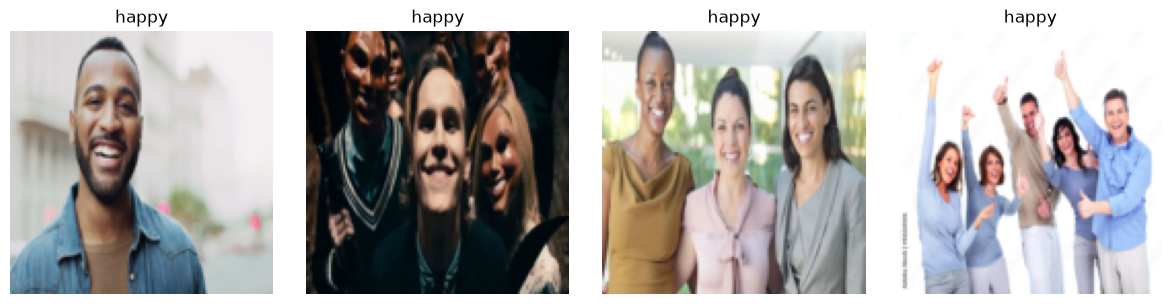

3단계 완료


In [9]:
class ImageDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            rgb_image = image.convert("RGB")
            tensor = self.transform(rgb_image)
        return tensor, label

raw_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.PILToTensor(),
])
data = ImageDataset(samples, raw_transform)

print("예시 이미지 불러오는 중...", flush=True)
preview_count = min(4, len(data))
fig, axes = plt.subplots(1, preview_count, figsize=(12, 3), squeeze=False)
for index in range(preview_count):
    image, label = data[index]
    axes[0, index].imshow(image.permute(1, 2, 0).numpy())
    axes[0, index].set_title(class_names[label])
    axes[0, index].axis("off")
plt.tight_layout()
plt.show()
print("3단계 완료", flush=True)


# 4. 이미지 값을 0~1로 바꾸기
`ToTensor()`가 값을 255로 나누고 모양을 `[3, 높이, 너비]`로 바꿉니다.
이후 코드에서 다시 255로 나누지 않습니다.


In [10]:
preprocess = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])
data.transform = preprocess

sample_image, sample_label = data[0]
print("모양:", tuple(sample_image.shape))
print("자료형:", sample_image.dtype)
print("값의 범위:", sample_image.min().item(), "~", sample_image.max().item())


모양: (3, 128, 128)
자료형: torch.float32
값의 범위: 0.0117647061124444 ~ 0.95686274766922


# 5. 학습 / 검증 / 평가 분할
각 클래스의 이미지를 약 70% / 20% / 나머지로 한 번만 나눕니다.
이미지 수를 정수로 나누기 때문에 비율은 조금 달라집니다.
각 파일은 한 부분에만 속합니다. 동일 이미지의 복사본이나 매우 비슷한 사진이 있다면 별도로 정리해야 합니다.

Windows Jupyter에서 사용할 수 있도록 `num_workers=0`으로 설정합니다.


In [12]:
rng = random.Random(SEED)
train_indices, val_indices, test_indices = [], [], []

for label in range(len(class_names)):
    indices = [i for i, (_, target) in enumerate(samples) if target == label]
    rng.shuffle(indices)

    count = len(indices)
    train_count = min(max(1, int(count * 0.7)), count - 2)
    val_count = min(max(1, int(count * 0.2)), count - train_count - 1)

    train_indices.extend(indices[:train_count])
    val_indices.extend(indices[train_count:train_count + val_count])
    test_indices.extend(indices[train_count + val_count:])

train_data = Subset(data, train_indices)
val_data = Subset(data, val_indices)
test_data = Subset(data, test_indices)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"학습: {len(train_data)}장 / {len(train_loader)}묶음")
print(f"검증: {len(val_data)}장 / {len(val_loader)}묶음")
print(f"평가: {len(test_data)}장 / {len(test_loader)}묶음")


학습: 213장 / 27묶음
검증: 60장 / 8묶음
평가: 32장 / 4묶음


# 6. 작은 CNN 만들기
세 번의 합성곱으로 이미지 특징을 추출하고 마지막에 두 종류를 구분합니다.
적응형 평균 풀링으로 마지막 층에 들어가는 값을 줄였습니다.
`BCEWithLogitsLoss`가 Sigmoid와 이진 분류 손실 계산을 함께 수행합니다.

이 셀을 다시 실행하면 모델이 새로 초기화됩니다. 학습 후 결과를 볼 때는 다시 실행하지 마세요.


In [13]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, images):
        return self.classifier(self.features(images)).squeeze(1)

print("모델 생성 및 GPU 이동 시작...", flush=True)
model = SmallCNN().to(device)
torch.xpu.synchronize()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, foreach=False
)

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": [], "seconds": []}
training_complete = False
run_dir = None
model_path = None

print("모델 위치:", next(model.parameters()).device, flush=True)
print("파라미터 수:", sum(p.numel() for p in model.parameters()), flush=True)
print("6단계 완료", flush=True)


모델 생성 및 GPU 이동 시작...
모델 위치: xpu:0
파라미터 수: 89249
6단계 완료


# 7. 학습 — 묶음마다 진행 상황 표시
처음 학습하는 묶음에서는 다음 순서를 자세히 표시합니다.

**이미지 읽기 → GPU 이동 → 예측 → 오차 계산 → 기울기 계산 → 가중치 수정**

이후에도 각 묶음이 끝날 때 처리 시간과 정확도를 출력합니다.
한 에포크가 끝날 때마다 해당 시점의 모델을 자동 저장합니다.
첫 에포크에만 필요한 준비 시간이 있을 수 있으므로 전체 시간을 단순히 확정하지 않습니다.

- 오류가 나면 마지막으로 출력된 단계와 오류 내용을 확인하세요.
- `[*]` 상태에서는 같은 셀을 다시 실행하지 마세요.
- 특정 단계에서 계속 멈춘다면 **Kernel → Interrupt Kernel**로 중단하고 그 단계를 알려주세요.
- GPU를 못 쓰면 자동으로 CPU 학습으로 바꾸지 않습니다.
- 처음부터 새로 학습하려면 커널을 재시작하고 위에서부터 실행하세요.
- 이 셀을 학습 완료 후 다시 실행하면 현재 가중치에서 추가로 `EPOCHS`회 학습합니다.


In [14]:
def run_epoch(loader, training, epoch_number):
    phase = "학습" if training else "검증"
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_count = 0
    iterator = iter(loader)

    print(f"\n에포크 {epoch_number} / {phase} 시작: {len(loader)}묶음", flush=True)
    with torch.set_grad_enabled(training):
        for step in range(1, len(loader) + 1):
            started = time.perf_counter()
            detailed = (step == 1)

            def stage(message):
                if detailed:
                    print(f"  [{phase} 첫 묶음] {message}", flush=True)

            stage("이미지 읽는 중")
            images, labels = next(iterator)
            stage("이미지 읽기 완료 → GPU로 이동 중")
            images = images.to(device)
            labels = labels.to(device, dtype=torch.float32)
            if detailed:
                torch.xpu.synchronize()

            if training:
                optimizer.zero_grad(set_to_none=True)

            stage("GPU 이동 완료 → 예측 계산 중")
            logits = model(images)
            if detailed:
                torch.xpu.synchronize()

            stage("예측 완료 → 오차 계산 중")
            loss = criterion(logits, labels)
            if detailed:
                torch.xpu.synchronize()

            if training:
                stage("오차 계산 완료 → 기울기 계산 중")
                loss.backward()
                if detailed:
                    torch.xpu.synchronize()
                stage("기울기 계산 완료 → 가중치 수정 중")
                optimizer.step()
                if detailed:
                    torch.xpu.synchronize()

            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise RuntimeError("손실값이 NaN 또는 무한대가 되었습니다. 학습을 중단합니다.")

            batch_count = labels.numel()
            total_loss += loss_value * batch_count
            total_correct += (
                (logits.detach() > 0) == (labels > 0.5)
            ).sum().item()
            total_count += batch_count

            elapsed = time.perf_counter() - started
            print(
                f"  {phase} {step:02d}/{len(loader)} 완료 | "
                f"{elapsed:.2f}초 | loss={loss_value:.4f} | "
                f"누적 정확도={total_correct / total_count:.1%}",
                flush=True,
            )

    return total_loss / total_count, total_correct / total_count


def save_model_snapshot(path):
    checkpoint = {
        "architecture": "SmallCNN-v1",
        "model_state_dict": {
            name: value.detach().cpu()
            for name, value in model.state_dict().items()
        },
        "class_names": list(class_names),
        "image_size": list(IMAGE_SIZE),
        "seed": SEED,
        "epochs_completed": len(history["loss"]),
        "history": history,
    }
    torch.save(checkpoint, path)


if EPOCHS < 1:
    raise ValueError("EPOCHS는 1 이상이어야 합니다.")
if run_dir is None:
    run_name = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    run_dir = PROJECT_DIR / "models" / f"pytorch_restart_{run_name}"
    run_dir.mkdir(parents=True, exist_ok=False)
    model_path = run_dir / "imageclassifier.pt"
    split_manifest = {
        name: [str(samples[i][0].relative_to(DATA_DIR)) for i in indices]
        for name, indices in [
            ("train", train_indices), ("validation", val_indices), ("test", test_indices)
        ]
    }
    (run_dir / "split.json").write_text(
        json.dumps(split_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

training_complete = False
completed_before = len(history["loss"])
session_start = time.perf_counter()
print("학습 장치:", device, flush=True)
print("자동 저장 위치:", model_path, flush=True)

try:
    for additional_epoch in range(1, EPOCHS + 1):
        epoch_number = completed_before + additional_epoch
        epoch_start = time.perf_counter()

        train_loss, train_acc = run_epoch(train_loader, True, epoch_number)
        val_loss, val_acc = run_epoch(val_loader, False, epoch_number)
        torch.xpu.synchronize()
        epoch_seconds = time.perf_counter() - epoch_start

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)
        history["seconds"].append(epoch_seconds)

        print("에포크 완료 → 모델 저장 중...", flush=True)
        save_model_snapshot(model_path)

        print(
            f"\n[에포크 {epoch_number} 저장 완료] "
            f"학습 정확도={train_acc:.1%}, 검증 정확도={val_acc:.1%}, "
            f"학습·검증 시간={epoch_seconds:.1f}초\n",
            flush=True,
        )

    training_complete = True
    print(
        f"학습 완료! 이번 실행에 {time.perf_counter() - session_start:.1f}초가 걸렸습니다.",
        flush=True,
    )
except KeyboardInterrupt:
    print(
        "\n학습을 중단했습니다. 완료된 에포크가 있다면 위 경로에 저장되어 있습니다. "
        "중단 원인을 확인한 후 진행하세요.",
        flush=True,
    )
    raise


학습 장치: xpu:0
자동 저장 위치: C:\Users\박정원\ImageClassification\models\pytorch_restart_20261022-114333-513465\imageclassifier.pt

에포크 1 / 학습 시작: 27묶음
  [학습 첫 묶음] 이미지 읽는 중
  [학습 첫 묶음] 이미지 읽기 완료 → GPU로 이동 중
  [학습 첫 묶음] GPU 이동 완료 → 예측 계산 중
  [학습 첫 묶음] 예측 완료 → 오차 계산 중
  [학습 첫 묶음] 오차 계산 완료 → 기울기 계산 중
  [학습 첫 묶음] 기울기 계산 완료 → 가중치 수정 중
  학습 01/27 완료 | 3.92초 | loss=0.6813 | 누적 정확도=75.0%
  학습 02/27 완료 | 0.29초 | loss=0.6846 | 누적 정확도=68.8%
  학습 03/27 완료 | 0.14초 | loss=0.7192 | 누적 정확도=58.3%
  학습 04/27 완료 | 0.07초 | loss=0.7112 | 누적 정확도=53.1%
  학습 05/27 완료 | 0.18초 | loss=0.6863 | 누적 정확도=55.0%
  학습 06/27 완료 | 0.07초 | loss=0.7025 | 누적 정확도=50.0%
  학습 07/27 완료 | 0.08초 | loss=0.6961 | 누적 정확도=48.2%
  학습 08/27 완료 | 0.14초 | loss=0.6904 | 누적 정확도=48.4%
  학습 09/27 완료 | 0.18초 | loss=0.6826 | 누적 정확도=52.8%
  학습 10/27 완료 | 0.10초 | loss=0.6817 | 누적 정확도=53.8%
  학습 11/27 완료 | 0.36초 | loss=0.6778 | 누적 정확도=55.7%
  학습 12/27 완료 | 0.27초 | loss=0.6880 | 누적 정확도=55.2%
  학습 13/27 완료 | 1.04초 | loss=0.6890 | 누적 정확도=54.8%
  학습 14/27 완료 |

# 8. 그래프와 소요 시간 보기
학습 정확도와 검증 정확도를 함께 확인합니다.
처음에는 동작을 확인하기 위해 3에포크로 설정했으므로 충분히 학습되지 않았을 수 있습니다.


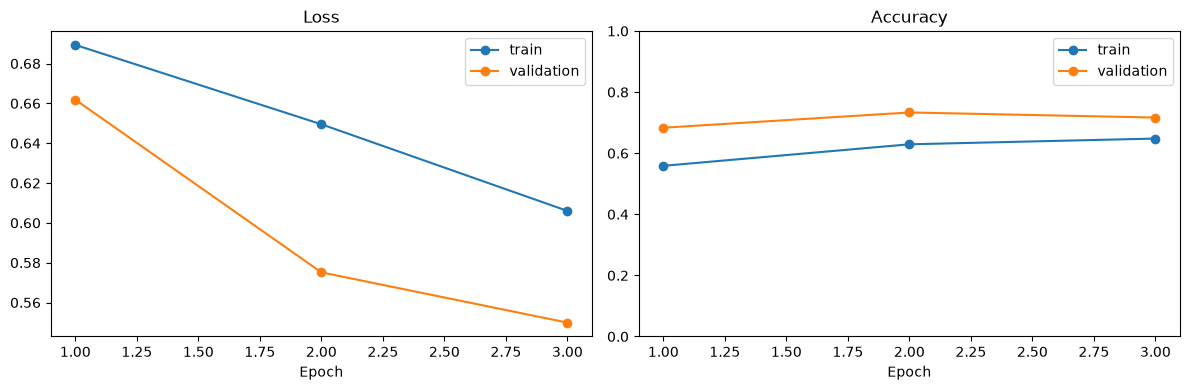

에포크 1: 학습·검증 12.6초
에포크 2: 학습·검증 7.1초
에포크 3: 학습·검증 7.1초


In [15]:
if not history["loss"]:
    raise RuntimeError("완료된 에포크가 없습니다. 먼저 7단계를 확인하세요.")

epochs = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["loss"], marker="o", label="train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, history["accuracy"], marker="o", label="train")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

for epoch, seconds in enumerate(history["seconds"], start=1):
    print(f"에포크 {epoch}: 학습·검증 {seconds:.1f}초")


# 9. Evaluate — 평가
학습·검증과 분리한 평가 이미지로 성능을 계산합니다.
첫 출력에 `평가 시작`이 나오고 각 묶음이 끝날 때 진행률이 표시됩니다.
정밀도와 재현율은 분류 번호 1을 기준으로 계산합니다.


In [16]:
if not training_complete:
    raise RuntimeError("7단계의 '학습 완료!' 출력을 먼저 확인하세요.")

model.eval()
tp = tn = fp = fn = 0
print(
    f"평가 시작: 이미지 {len(test_data)}장, {len(test_loader)}묶음",
    flush=True,
)
evaluation_start = time.perf_counter()
iterator = iter(test_loader)

with torch.no_grad():
    for step in range(1, len(test_loader) + 1):
        print(f"평가 {step}/{len(test_loader)}: 이미지 읽기 및 예측 중", flush=True)
        images, labels = next(iterator)
        logits = model(images.to(device))
        # 예측 결과를 CPU로 받아 계산합니다.
        predicted = (logits > 0).to("cpu")
        positive = labels == 1

        tp += (predicted & positive).sum().item()
        tn += ((~predicted) & (~positive)).sum().item()
        fp += (predicted & (~positive)).sum().item()
        fn += ((~predicted) & positive).sum().item()
        print(f"평가 {step}/{len(test_loader)} 완료", flush=True)

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else float("nan")
recall = tp / (tp + fn) if tp + fn else float("nan")

print("\n평가 완료", flush=True)
print(f"소요 시간: {time.perf_counter() - evaluation_start:.2f}초")
print("정밀도/재현율 기준 클래스:", class_names[1])
print(f"Accuracy : {accuracy:.1%}")
print(f"Precision: {precision:.1%}")
print(f"Recall   : {recall:.1%}")
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")
print("NaN이 나오면 해당 지표의 분모가 0이어서 계산할 수 없다는 뜻입니다.")


평가 시작: 이미지 32장, 4묶음
평가 1/4: 이미지 읽기 및 예측 중
평가 1/4 완료
평가 2/4: 이미지 읽기 및 예측 중
평가 2/4 완료
평가 3/4: 이미지 읽기 및 예측 중
평가 3/4 완료
평가 4/4: 이미지 읽기 및 예측 중
평가 4/4 완료

평가 완료
소요 시간: 1.38초
정밀도/재현율 기준 클래스: sad
Accuracy : 84.4%
Precision: 100.0%
Recall   : 68.8%
TP=11, TN=16, FP=0, FN=5
NaN이 나오면 해당 지표의 분모가 0이어서 계산할 수 없다는 뜻입니다.


# 10. 이미지 한 장 예측
`image_path`를 바꾸면 원하는 이미지로 예측할 수 있습니다.
사진을 RGB로 읽고 학습 때와 같은 크기·값 범위로 처리합니다.
출력 확률은 모델의 계산값이며 정답을 보장하는 수치가 아닙니다.


이미지 예측 시작: C:\Users\박정원\ImageClassification\the test for the model.jpg
예측: happy
happy: 59.1%
sad: 40.9%


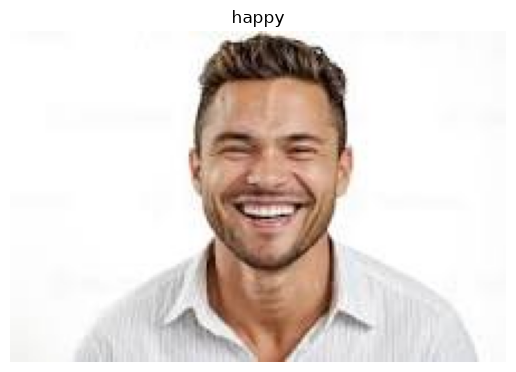

In [20]:
def predict_image(network, path, image_transform, names):
    with Image.open(path) as image:
        rgb_image = image.convert("RGB")
    tensor = image_transform(rgb_image).unsqueeze(0).to(device)
    network.eval()
    with torch.no_grad():
        probability_1 = torch.sigmoid(network(tensor)).item()
    return rgb_image, names[int(probability_1 > 0.5)], probability_1

if not training_complete:
    raise RuntimeError("7단계의 학습을 먼저 완료하세요.")

image_path = PROJECT_DIR / "the test for the model.jpg"
if not image_path.is_file():
    image_path = samples[test_indices[0]][0]

# 원하는 이미지로 바꾸는 예:
# image_path = Path(r"C:\Users\박정원\Pictures\sample.jpg")

print("이미지 예측 시작:", image_path, flush=True)
image, predicted_name, probability_1 = predict_image(
    model, image_path, preprocess, class_names
)
print("예측:", predicted_name)
print(f"{class_names[0]}: {1 - probability_1:.1%}")
print(f"{class_names[1]}: {probability_1:.1%}")

plt.imshow(image)
plt.title(predicted_name)
plt.axis("off")
plt.show()


# 11. 저장된 모델 다시 불러오기
7단계에서 매 에포크 완료 후 `models/pytorch_restart_실행시각/imageclassifier.pt`에 저장됩니다.
각 실행의 폴더가 다르므로 이전 실행의 결과도 남습니다.

아래 코드는 저장된 가중치·클래스 이름·이미지 크기를 불러옵니다.
저장 파일은 **예측용 가중치**입니다. 학습을 정확히 중단 지점부터 재개하는 optimizer 상태는 포함하지 않습니다.

새 커널에서 저장 파일을 사용하려면 import, GPU 설정, `SmallCNN` 클래스 정의와 `predict_image` 함수 정의를 실행하고
`model_path`에 저장 파일 경로를 직접 지정합니다. 학습 반복문을 다시 실행할 필요는 없습니다.


In [21]:
if model_path is None or not model_path.is_file():
    raise FileNotFoundError("저장된 모델이 없습니다. 먼저 7단계를 완료하세요.")

print("저장된 모델 읽는 중:", model_path, flush=True)
checkpoint = torch.load(model_path, map_location="cpu", weights_only=True)
if checkpoint["architecture"] != "SmallCNN-v1":
    raise ValueError("이 노트북의 SmallCNN 모델과 다른 저장 파일입니다.")

# 현재 모델에 저장된 가중치를 불러옵니다.
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
saved_names = checkpoint["class_names"]
saved_transform = transforms.Compose([
    transforms.Resize(tuple(checkpoint["image_size"])),
    transforms.ToTensor(),
])

_, saved_prediction, saved_probability_1 = predict_image(
    model, image_path, saved_transform, saved_names
)
print("불러오기 완료")
print("저장된 학습 에포크:", checkpoint["epochs_completed"])
print("저장된 클래스 순서:", saved_names)
print("불러온 모델의 예측:", saved_prediction)
print("저장 파일:", model_path)


저장된 모델 읽는 중: C:\Users\박정원\ImageClassification\models\pytorch_restart_20261022-114333-513465\imageclassifier.pt
불러오기 완료
저장된 학습 에포크: 3
저장된 클래스 순서: ['happy', 'sad']
불러온 모델의 예측: happy
저장 파일: C:\Users\박정원\ImageClassification\models\pytorch_restart_20261022-114333-513465\imageclassifier.pt


## 멈춘 것처럼 보일 때
- 첫 GPU 계산 단계에서 멈춤: 기본 GPU 실행 또는 드라이버 쪽 확인이 필요합니다.
- 이미지 읽기 단계에서 멈춤: 파일 경로와 해당 이미지의 읽기 상태를 확인합니다.
- 예측·기울기·가중치 수정 단계에서 멈춤: 마지막으로 출력된 단계와 오류 메시지를 확인합니다.
- GPU 메모리 부족 오류: `BATCH_SIZE=4`로 줄이고 커널을 재시작하여 처음부터 실행합니다.
- 커널이 실행 중이면 새 셀을 눌러도 앞의 작업이 끝나기를 기다릴 수 있습니다.
- 커널 재시작 후에는 Python 변수들이 없어지므로 필요한 셀을 위에서부터 다시 실행합니다.

이 파일의 코드 문법과 노트북 형식은 작성 시 확인합니다.
실제 GPU 학습의 완료 여부는 이 노트북을 실행한 출력으로 확인해야 합니다.

공식 참고 자료:
- [PyTorch Intel GPU 설치와 학습](https://docs.pytorch.org/docs/2.14/notes/get_start_xpu.html)
- [GPU 계산 완료 기다리기](https://docs.pytorch.org/docs/2.14/generated/torch.xpu.synchronize.html)
- [적응형 평균 풀링](https://docs.pytorch.org/docs/2.14/generated/torch.nn.AdaptiveAvgPool2d.html)
- [이진 분류 손실 함수](https://docs.pytorch.org/docs/2.14/generated/torch.nn.BCEWithLogitsLoss.html)
